In [ ]:
import os
import pandas as pd
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import cm
import seaborn as sns
#sns.set(style='whitegrid')
sns.set(style='whitegrid')

dataset = 'fineweb'
scion_methods = ['constrained_scion'] # unconstrained_scion or constrained_scion or projected_scion
loss_datasets = ['train', 'val'] # train or val
alphas = [
        1.0,
        # 0.5
        ]
epochs=5100
out_folder="out"



2 [np.float64(3.6656222343444815), np.float64(3.6291074752807617), np.float64(3.611424684524536), np.float64(3.657060384750366), np.float64(3.802886724472046)]
4 [np.float64(3.484238386154175), np.float64(3.4267468452453613), np.float64(3.418320894241333), np.float64(3.4512383937835693), np.float64(3.639195919036865)]
8 [np.float64(3.340958833694458), np.float64(3.28236722946167), np.float64(3.278909683227539), np.float64(3.3210482597351074), np.float64(3.5043656826019287)]
16 [np.float64(3.2275702953338623), np.float64(3.1838409900665283), np.float64(3.1650521755218506), np.float64(3.217004537582397), np.float64(3.399897813796997)]
32 [np.float64(3.1424007415771484), np.float64(3.095909357070923), np.float64(3.082383871078491), np.float64(3.1267008781433105), np.float64(3.2862048149108887)]


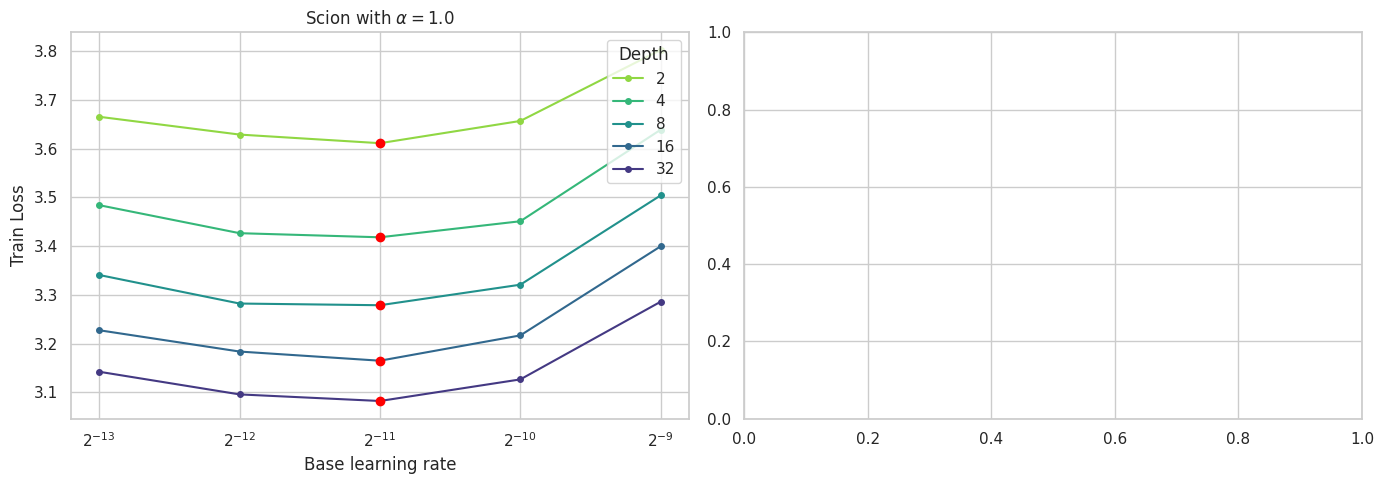

2 [np.float64(3.7287614345550537), np.float64(3.687425374984741), np.float64(3.676568746566773), np.float64(3.719537496566773), np.float64(3.858699083328247)]
4 [np.float64(3.5393192768096924), np.float64(3.487941026687622), np.float64(3.475665330886841), np.float64(3.507561445236206), np.float64(3.6951186656951904)]
8 [np.float64(3.3961493968963623), np.float64(3.3427047729492188), np.float64(3.339433431625366), np.float64(3.3749444484710693), np.float64(3.5616862773895264)]
16 [np.float64(3.286144256591797), np.float64(3.2375895977020264), np.float64(3.230391025543213), np.float64(3.2740609645843506), np.float64(3.457051515579224)]
32 [np.float64(3.2043163776397705), np.float64(3.1522326469421387), np.float64(3.1432697772979736), np.float64(3.180335283279419), np.float64(3.342868566513061)]


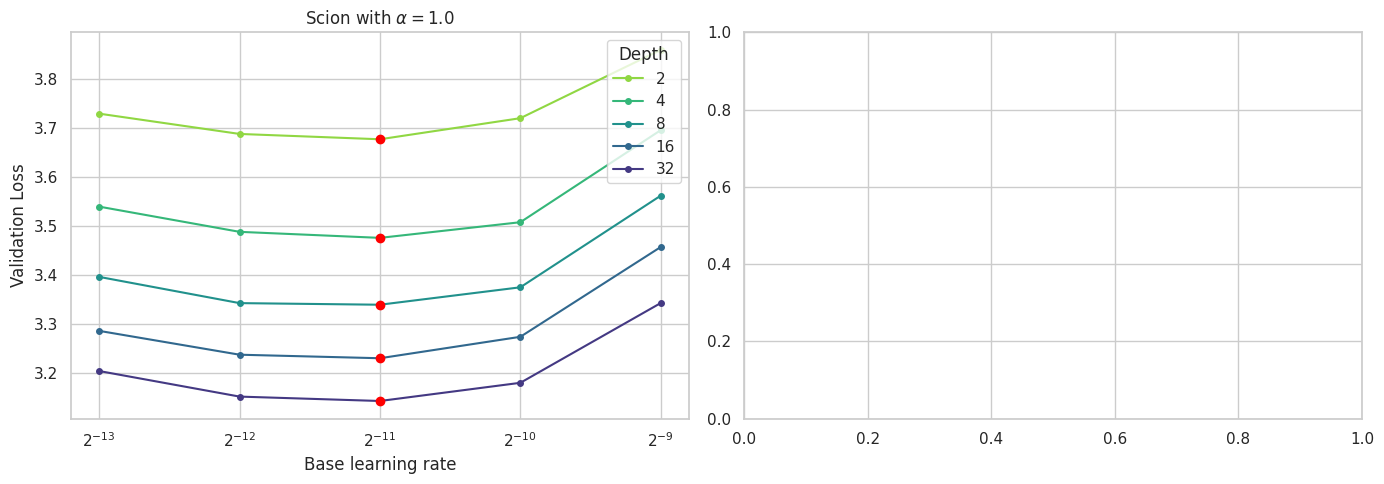

In [ ]:
METHOD_MAP = {
    # 'unconstrained_scion': 'Unconstrained Scion',
    # 'projected_scion': 'Projected Scion',
    'constrained_scion': 'Scion'
}

widths = [256]
depths = [2, 4, 8, 
           16, 
            32
          ]
lrs = [0.0001220703125, 0.000244140625, 0.00048828125, 0.0009765625, 0.001953125, 
]
        
for alpha in alphas:
    for loss_dataset in loss_datasets:
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        axs = axes.ravel()
        
        for i, scion_method in enumerate(scion_methods):
            parameterization_str = METHOD_MAP.get(scion_method, scion_method)
            extra = 'Spectral'
            ax = axs[i]

            optimal_lrs = []
            optimal_losses = []
            palette = sns.color_palette("viridis", n_colors=len(depths))

            for depth_idx, depth in enumerate(depths):
                seeds = [1]
                
                mean_losses = []
                sem_losses = []
                lrs_to_plot = []

                for lr in lrs:
                    losses = []
                    for seed in seeds:
                        for width in widths:
                            if scion_method == 'scion_full':
                                job_name = f'mode{extra}_width{width}_depth2_seed{seed}_lr{lr:.20f}'.rstrip('0')
                            else:
                                job_name = f'first_layer{extra}_width{width}_depth{depth}_seed{seed}_lr{lr:.20f}'.rstrip('0')

                            csv_path = os.path.join(
                                f'depthtransfer_{dataset}_with_Z/{out_folder}/{scion_method}_out', 
                                f'hptransferdepth_alpha_skipconnection_{alpha}_spectral_sign__depth{depth}_seed{seed}_lr{lr}', 
                                'log.csv'
                            )
                           
                            if os.path.exists(csv_path):
                                ckpt_df = pd.read_csv(csv_path, header=1, skip_blank_lines=True)
                                losses.append(ckpt_df[f'{loss_dataset}/loss'].values[-1])
                                # losses.append(ckpt_df[f'{loss_dataset}/loss'].ewm(alpha=0.8).mean().values[-1]) # CompleteP
                                # losses.append(ckpt_df[f'{loss_dataset}/loss'].min())
                            else:
                                print(f'Missing {csv_path}')

                    if losses:
                        mean_val = np.mean(losses)
                        mean_losses.append(mean_val)
                        lrs_to_plot.append(lr)
                        if len(seeds) > 1:
                            sem_losses.append(np.std(losses, ddof=1) / np.sqrt(len(losses)))

                # Plots
                print(depth, mean_losses)
                if mean_losses:
                    color = palette[len(depths) - depth_idx - 1]
                    ax.plot(lrs_to_plot, mean_losses, label=depth, color=color, marker='o', markersize=4)
                    
                    if len(seeds) > 1 and sem_losses:
                        ax.fill_between(lrs_to_plot, 
                                        np.array(mean_losses) - np.array(sem_losses), 
                                        np.array(mean_losses) + np.array(sem_losses), 
                                        color=color, alpha=0.33)

                    optimum_idx = np.argmin(mean_losses)
                    optimal_lrs.append(lrs_to_plot[optimum_idx])
                    optimal_losses.append(mean_losses[optimum_idx])
        
            ax.plot(optimal_lrs, optimal_losses, color='red', linestyle='none', marker='o')
            ax.set_xscale('log', base=2)
            ax.set_xlabel('Base learning rate')
            # ax.set_ylim(3,5)
            ax.set_title(f"{parameterization_str} with " + r"$\alpha =$" + f"{alpha}")
            if i==0:
                ax.legend(title='Depth', loc='upper right')

            if i == 0:
                ax.set_ylabel(f'{"Validation" if loss_dataset=="val" else "Train"} Loss')
            else:
                ax.yaxis.set_ticklabels([])
                ax.tick_params(axis='y', length=0)

        plt.tight_layout()
        # plt.savefig(f"GPT_with_Z_{dataset}_{out_folder}depth_transfer_scion_and_uscion_alpha_{alpha}_{loss_dataset}_loss_{epochs}_epochs_{len(seeds)}_seeds.pdf")
        plt.show()
        plt.close()

0 train
1 val


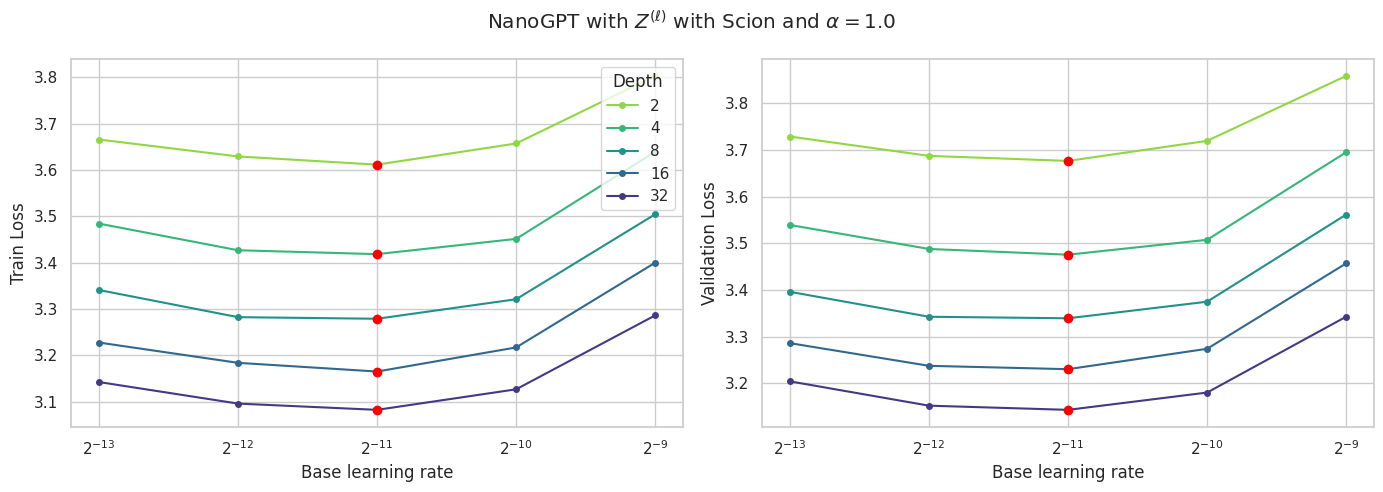

In [6]:
METHOD_MAP = {
    'unconstrained_scion': 'Unconstrained Scion',
    'projected_scion': 'Projected Scion',
    'constrained_scion': 'Scion'
}

widths = [256]
depths = [2, 4, 8, 16, 
           32
          ]
lrs = [
    # 0.001953125, 0.0009765625,
    # 3.0517578125e-05, 6.103515625e-05, 
    0.0001220703125, 0.000244140625, 0.00048828125,
    0.0009765625, 0.001953125, 
    # 0.00390625, 0.0078125
]
        
alpha=1.0
scion_method='constrained_scion'

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axs = axes.ravel()

for i, loss_dataset in enumerate(loss_datasets):
    ax = axs[i]
    print(i, loss_dataset)
    parameterization_str = METHOD_MAP.get(scion_method, scion_method)
    extra = 'Spectral'

    optimal_lrs = []
    optimal_losses = []
    palette = sns.color_palette("viridis", n_colors=len(depths))

    for depth_idx, depth in enumerate(depths):
        seeds = [1]
        
        mean_losses = []
        sem_losses = []
        lrs_to_plot = []

        for lr in lrs:
            losses = []
            for seed in seeds:
                for width in widths:
                    if scion_method == 'scion_full':
                        job_name = f'mode{extra}_width{width}_depth2_seed{seed}_lr{lr:.20f}'.rstrip('0')
                    else:
                        job_name = f'first_layer{extra}_width{width}_depth{depth}_seed{seed}_lr{lr:.20f}'.rstrip('0')

                    csv_path = os.path.join(
                        f'depthtransfer_{dataset}_with_Z/{out_folder}/{scion_method}_out', 
                        f'hptransferdepth_alpha_skipconnection_{alpha}_spectral_sign__depth{depth}_seed{seed}_lr{lr}', 
                        'log.csv'
                    )

                    if os.path.exists(csv_path):
                        ckpt_df = pd.read_csv(csv_path, header=1, skip_blank_lines=True)
                        losses.append(ckpt_df[f'{loss_dataset}/loss'].values[-1])
                        # losses.append(ckpt_df[f'{loss_dataset}/loss'].ewm(alpha=0.8).mean().values[-1]) # CompleteP
                        # losses.append(ckpt_df[f'{loss_dataset}/loss'].min())
                    else:
                        print(f'Missing {csv_path}')

            if losses:
                mean_val = np.mean(losses)
                mean_losses.append(mean_val)
                lrs_to_plot.append(lr)
                if len(seeds) > 1:
                    sem_losses.append(np.std(losses, ddof=1) / np.sqrt(len(losses)))

        # Plots
        if mean_losses:
            color = palette[len(depths) - depth_idx - 1]
            ax.plot(lrs_to_plot, mean_losses, label=depth, color=color, marker='o', markersize=4)
            
            if len(seeds) > 1 and sem_losses:
                ax.fill_between(lrs_to_plot, 
                                np.array(mean_losses) - np.array(sem_losses), 
                                np.array(mean_losses) + np.array(sem_losses), 
                                color=color, alpha=0.33)

            optimum_idx = np.argmin(mean_losses)
            optimal_lrs.append(lrs_to_plot[optimum_idx])
            optimal_losses.append(mean_losses[optimum_idx])
        
        # ax.plot(lrs_to_plot[optimum_idx], mean_losses[optimum_idx], color=color, linestyle='none', marker='*', markersize=10)

    ax.plot(optimal_lrs, optimal_losses, color='red', linestyle='none', marker='o')
    ax.set_xscale('log', base=2)
    ax.set_xlabel('Base learning rate')
    # ax.set_title(f"{parameterization_str} with " + r"$\alpha =$" + f"{alpha}")
    if i==0:
        ax.legend(title='Depth', loc='upper right')


    ax.set_ylabel(f'{"Validation" if loss_dataset=="val" else "Train"} Loss')

plt.suptitle(r"NanoGPT with $Z^{(\ell)}$ with Scion and $\alpha=1.0$")
plt.tight_layout()
plt.savefig(f"GPT_with_Z_{dataset}_{out_folder}depth_transfer_scion_and_uscion_alpha_{alpha}_{loss_dataset}_loss_{epochs}_epochs_{len(seeds)}_seeds.pdf")
plt.show()
plt.close()

In [ ]:
# TABLE
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

METHOD_MAP = {
    'unconstrained_scion': 'Unconstrained Scion',
    'projected_scion': 'Projected Scion',
    'constrained_scion': 'Scion'
}

alpha=1.0
widths = [256]
depths = [
    # 2,
      4, 
    # 8, 16, 
          32]
lrs = [0.001953125, 0.0009765625, 0.00048828125, 0.000244140625, 0.0001220703125, 6.103515625e-05]
extra = 'Spectral'

all_results = []

print("Collecting data...")
for scion_method in scion_methods:
    for depth in depths:
        seeds = [1, 2, 3]
        for lr in lrs:
            seed_losses_train = []
            seed_losses_val = []
            
            for seed in seeds:
                for width in widths:
                    # Path logic
                    csv_path = os.path.join(
                        f'depthtransfer_{dataset}/{out_folder}/{scion_method}_out', 
                        f'hptransferdepth_alpha_skipconnection_{alpha}_spectral_sign__depth{depth}_seed{seed}_lr{lr}', 
                        'log.csv'
                    )

                    if os.path.exists(csv_path):
                        try:
                            # header=1 to match your specific log format
                            df = pd.read_csv(csv_path, header=1, skip_blank_lines=True)
                            seed_losses_train.append(df['train/loss'].values[-1])
                            seed_losses_val.append(df['val/loss'].values[-1])
                        except Exception:
                            pass
            
            if seed_losses_train:
                all_results.append({
                    'Method': METHOD_MAP.get(scion_method, scion_method),
                    'Depth': depth,
                    'LR': lr,
                    'train_loss': np.mean(seed_losses_train),
                    'val_loss': np.mean(seed_losses_val),
                    'train_sem': np.std(seed_losses_train, ddof=1) / np.sqrt(len(seed_losses_train)) if len(seed_losses_train) > 1 else 0,
                    'val_sem': np.std(seed_losses_val, ddof=1) / np.sqrt(len(seed_losses_val)) if len(seed_losses_val) > 1 else 0
                })

# Convert to master DataFrame
master_df = pd.DataFrame(all_results)

print("\n" + "="*50)
print(f" PIVOT TABLE FOR ALPHA = {alpha}")
print("="*50)

pivot_table = master_df.pivot_table(
    index=['Method', 'Depth', 'LR'],
    values=['train_loss', 'val_loss']
)

# Reorder columns
pivot_table = pivot_table[['train_loss', 'val_loss']]

# Display in console
print(pivot_table.to_string(float_format=lambda x: "{:,.6f}".format(x)))

csv_filename = f"GPT_results_alpha_{alpha}.csv"
# pivot_table.reset_index().to_csv(csv_filename, index=False)
print(f"\n[INFO] Table saved to {csv_filename}")
